<a href="https://colab.research.google.com/github/Workhong/Classification-Stock-Strategy/blob/main/HW3_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW3 – Classification: Best Investment Strategy per Stock

**Goal:** predict which of three investment strategies works best for a stock.
* 10 years of data for 214 U.S. stocks, with 11 features and 1 target.
* Classes (`Best_Strategy`): `DCA_Buy_Hold`, `Drawdown_60%`, `Yearly_Sept_buy_April_sell`
* Models compared: MLP, Deep Learning and XGBoost
* Evaluation: accuracy, precision, recall, F1-measure, confusion matrix


## Libraries

In [129]:
!pip -q install onnx onnxruntime onnxmltools onnxscript openpyxl mlxtend

In [130]:
import numpy as np
import torch
import pandas as pd
import sklearn
import random
import json
import os

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [131]:
import matplotlib.pyplot as plt

from mlxtend.plotting import heatmap
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

In [132]:
import xgboost as xgb

In [133]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score

In [134]:
import onnxruntime as rt
import onnx
import onnxmltools

from onnxmltools.convert.common.data_types import FloatTensorType   ## it is imported from onnxmltools instead (needed for convert_xgboost).

## Parameters

In [135]:
## 0.001, 0.0001, 0.0003, 0.01, 0.03

batch_size    = 16
learning_rate = 0.003 ## 0.001 worse
N_Epochs      = 2000  ## 4000 worse

epsilon = 0.0001

random_seed = 42      ## fixed so the report results can be reproduced
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)

## Read data

In [136]:
from google.colab import drive
drive.mount('/content/drive')

path_data = '/content/drive/MyDrive/HW3/Raw Data_3.xlsx'

stock_raw_data = pd.read_excel( path_data )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [137]:
stock_raw_data

,Symbol,Sector,Industry,10Y Return (Annualized) (%),Risk / Return Rank (1Y),Sharpe Ratio,Sortino Ratio,Omega Ratio,Martin Ratio,Calmar Ratio,Ulcer Index (%),Best_Strategy
0,CLS,Technology,Electronic Components,34.98,41.77,-0.2698,0.1556,1.0187,-0.8977,-0.3836,24.13,Drawdown60
1,NVDA,Technology,Semiconductors,54.09,27.73,-0.4246,-0.3519,0.9598,-1.7582,-0.5131,9.32,DCA_Buy_Hold
2,MU,Technology,Semiconductors,46.38,96.63,2.6954,2.8726,1.3497,13.7925,4.9397,16.44,Year_Sept_April
3,NTRA,Healthcare,Diagnostics & Research,39.85,85.27,1.0690,1.6256,1.2186,4.1900,1.9346,13.27,Drawdown60
4,AMD,Technology,Semiconductors,54.97,91.53,1.5332,2.0955,1.2658,7.8407,2.9777,14.39,DCA_Buy_Hold
...,...,...,...,...,...,...,...,...,...,...,...,...
209,STE,Healthcare,Medical Devices,16.31,49.92,-0.0404,0.1330,1.0158,-0.0699,-0.0422,15.33,DCA_Buy_Hold
210,EONGY,Utilities,Utilities - Diversified,16.43,79.03,0.8738,1.2678,1.1608,2.9038,1.2496,7.41,Year_Sept_April
211,TEAM,Technology,Software - Application,18.49,53.68,-0.0631,0.5362,1.0605,-0.1378,-0.0774,36.68,DCA_Buy_Hold
212,RMD,Healthcare,Medical Instruments & Supplies,16.12,42.02,-0.2492,-0.1303,0.9833,-0.4310,-0.2293,17.77,DCA_Buy_Hold


## Encode categorical columns


In [138]:
sector_names   = sorted( stock_raw_data['Sector'].dropna().unique() )
industry_names = sorted( stock_raw_data['Industry'].dropna().unique() )
strategy_names = sorted( stock_raw_data['Best_Strategy'].dropna().unique() )

sector_map   = { name: i for i, name in enumerate(sector_names)   }
industry_map = { name: i for i, name in enumerate(industry_names) }
strategy_map = { name: i for i, name in enumerate(strategy_names) }

print('Sector map:',   sector_map)
print('Industry map:', industry_map)
print('Strategy map:', strategy_map)

stock_raw_data['Sector']        = stock_raw_data['Sector'].map(sector_map)
stock_raw_data['Industry']      = stock_raw_data['Industry'].map(industry_map)
stock_raw_data['Best_Strategy'] = stock_raw_data['Best_Strategy'].map(strategy_map)

Sector map: {'Basic Materials': 0, 'Communication Services': 1, 'Consumer Cyclical': 2, 'Consumer Defensive': 3, 'Energy': 4, 'Financial Services': 5, 'Healthcare': 6, 'Industrials': 7, 'Real Estate': 8, 'Technology': 9, 'Utilities': 10}
Industry map: {'Aerospace & Defense': 0, 'Apparel Manufacturing': 1, 'Apparel Retail': 2, 'Asset Management': 3, 'Auto Manufacturers': 4, 'Banks - Diversified': 5, 'Banks - Regional': 6, 'Biotechnology': 7, 'Capital Markets': 8, 'Communication Equipment': 9, 'Computer Hardware': 10, 'Conglomerates': 11, 'Consumer Electronics': 12, 'Copper': 13, 'Credit Services': 14, 'Diagnostics & Research': 15, 'Discount Stores': 16, 'Drug Manufacturers - General': 17, 'Electrical Equipment & Parts': 18, 'Electronic Components': 19, 'Electronic Gaming & Multimedia': 20, 'Engineering & Construction': 21, 'Entertainment': 22, 'Farm & Heavy Construction Machinery': 23, 'Financial Data & Stock Exchanges': 24, 'Gold': 25, 'Grocery Stores': 26, 'Health Information Services

In [139]:
stock_raw_data

,Symbol,Sector,Industry,10Y Return (Annualized) (%),Risk / Return Rank (1Y),Sharpe Ratio,Sortino Ratio,Omega Ratio,Martin Ratio,Calmar Ratio,Ulcer Index (%),Best_Strategy
0,CLS,9,19,34.98,41.77,-0.2698,0.1556,1.0187,-0.8977,-0.3836,24.13,1
1,NVDA,9,58,54.09,27.73,-0.4246,-0.3519,0.9598,-1.7582,-0.5131,9.32,0
2,MU,9,58,46.38,96.63,2.6954,2.8726,1.3497,13.7925,4.9397,16.44,2
3,NTRA,6,15,39.85,85.27,1.0690,1.6256,1.2186,4.1900,1.9346,13.27,1
4,AMD,9,58,54.97,91.53,1.5332,2.0955,1.2658,7.8407,2.9777,14.39,0
...,...,...,...,...,...,...,...,...,...,...,...,...
209,STE,6,40,16.31,49.92,-0.0404,0.1330,1.0158,-0.0699,-0.0422,15.33,0
210,EONGY,10,70,16.43,79.03,0.8738,1.2678,1.1608,2.9038,1.2496,7.41,2
211,TEAM,9,59,18.49,53.68,-0.0631,0.5362,1.0605,-0.1378,-0.0774,36.68,0
212,RMD,6,42,16.12,42.02,-0.2492,-0.1303,0.9833,-0.4310,-0.2293,17.77,0


## Select features and target

In [140]:
stock_data = stock_raw_data.copy()

## Best_Strategy is the target, Symbol is only an identifier
feature_columns = [ c for c in stock_data.columns if c not in ['Symbol', 'Best_Strategy'] ]

for col in feature_columns:
    stock_data[col] = pd.to_numeric( stock_data[col], errors='coerce' )

stock_data = stock_data.dropna( subset=['Best_Strategy'] ).reset_index(drop=True)

headers_list = feature_columns + ['Best_Strategy']

n_features = len(feature_columns)
n_classes  = len(strategy_names)

print('Input columns:', feature_columns)
print('Number of features:', n_features)
print('Number of classes:',  n_classes)

Input columns: ['Sector', 'Industry', '10Y Return (Annualized) (%)', 'Risk / Return Rank (1Y)', 'Sharpe Ratio', 'Sortino Ratio', 'Omega Ratio', 'Martin Ratio', 'Calmar Ratio', 'Ulcer Index (%)']
Number of features: 10
Number of classes: 3


In [141]:
headers_list

['Sector',
 'Industry',
 '10Y Return (Annualized) (%)',
 'Risk / Return Rank (1Y)',
 'Sharpe Ratio',
 'Sortino Ratio',
 'Omega Ratio',
 'Martin Ratio',
 'Calmar Ratio',
 'Ulcer Index (%)',
 'Best_Strategy']

## Data Analysis

* Correlation matrix


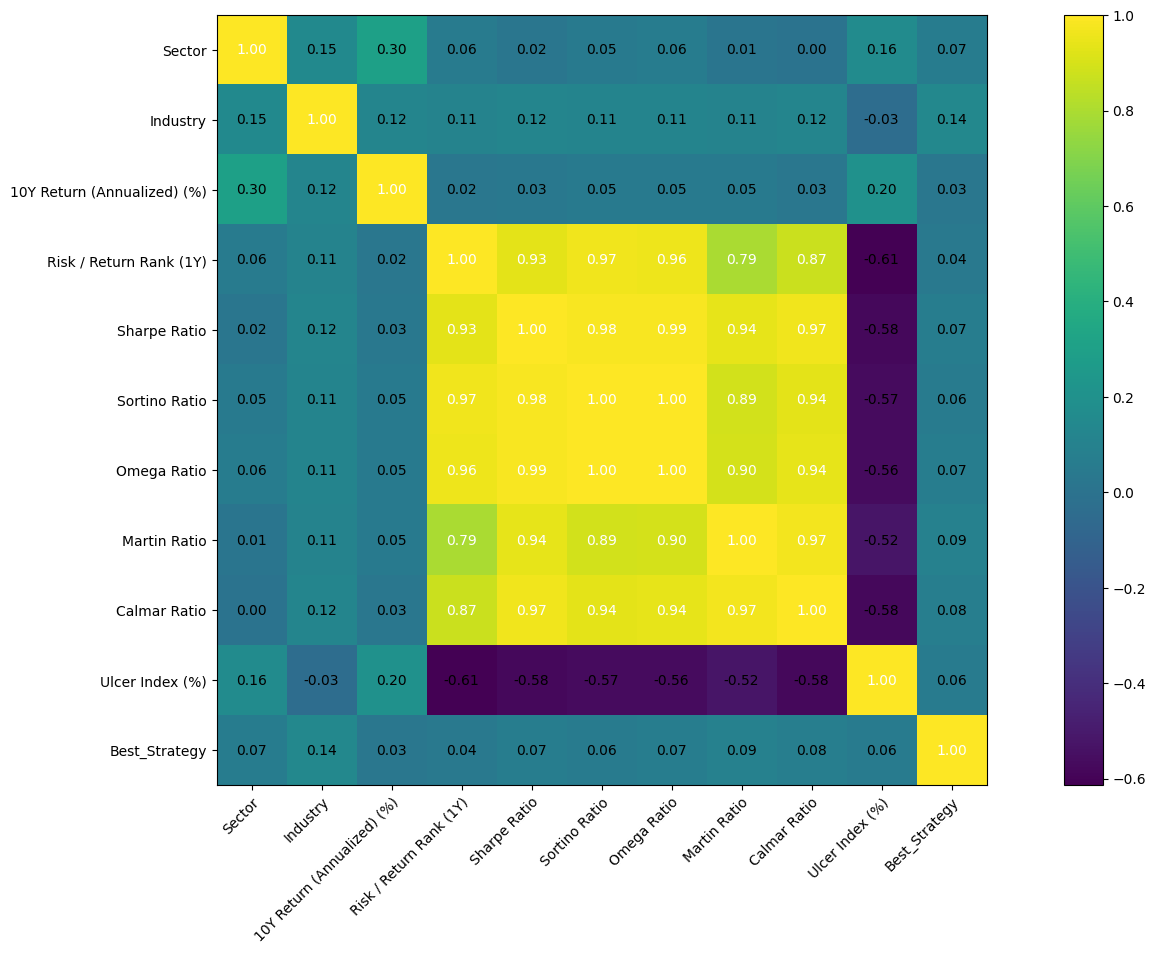

In [142]:
cm_data = stock_data[headers_list].fillna( stock_data[headers_list].median() )

cm = np.corrcoef(   cm_data.values.T   )
hm = heatmap(cm, row_names=headers_list, column_names=headers_list, figsize=(20,10))
plt.show()

In [143]:
## correlation of each feature with the target
pd.Series( cm[-1, :-1], index=feature_columns ).sort_values()

,0
10Y Return (Annualized) (%),0.028041
Risk / Return Rank (1Y),0.039148
Sortino Ratio,0.056873
Ulcer Index (%),0.058282
Sector,0.065297
Omega Ratio,0.067513
Sharpe Ratio,0.073264
Calmar Ratio,0.075335
Martin Ratio,0.093619
Industry,0.141524


## Process Data

In [144]:
## Convert Pandas to Numpy

X = stock_data[feature_columns].to_numpy()

y = stock_data[['Best_Strategy']].to_numpy()

In [145]:
y = y.astype(int)

y[:10]

array([[1],
       [0],
       [2],
       [1],
       [0],
       [1],
       [1],
       [0],
       [2],
       [1]])

In [146]:
the_set = np.unique(y)

the_set

array([0, 1, 2])

In [147]:
len(  the_set  )

3

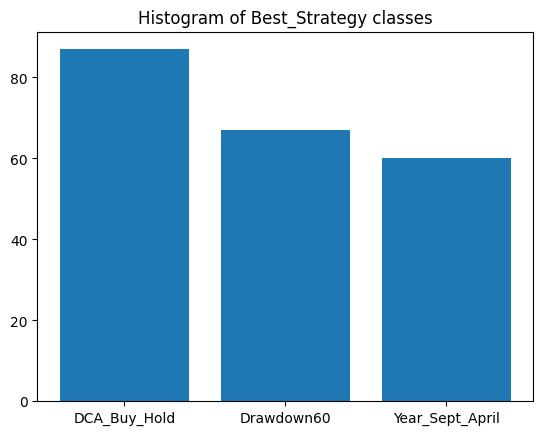

In [148]:
_ = plt.hist(y, bins=np.arange(n_classes + 1) - 0.5, rwidth=0.8)

plt.xticks( range(n_classes), strategy_names )
plt.title("Histogram of Best_Strategy classes")

plt.show()

In [149]:
print(X.shape)

print(y.shape)

(214, 10)
(214, 1)


## Train / test split

`stratify=y` keeps the same class proportions in train and test

In [150]:
X_train, X_test, y_train, y_test, sym_train, sym_test = train_test_split(
    X, y, stock_data['Symbol'].to_numpy(),
    test_size=0.2, random_state=random_seed, stratify=y
)

In [151]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(171, 10)
(43, 10)
(171, 1)
(43, 1)


## Fill missing values

Missing values are filled with the **training** medians.

In [152]:
train_medians = np.nanmedian( X_train.astype(float), axis=0 )

X_train = np.where( np.isnan(X_train.astype(float)), train_medians, X_train )
X_test  = np.where( np.isnan(X_test.astype(float)),  train_medians, X_test  )

print('Missing values left:', np.isnan(X_train.astype(float)).sum(), np.isnan(X_test.astype(float)).sum())

Missing values left: 0 0


In [153]:
## fix data type

X_train = X_train.astype(  np.float32  )
X_test  = X_test.astype(   np.float32  )
y_train = y_train.astype(  np.int64 )       ## np.long
y_test  = y_test.astype(   np.int64 )

In [154]:
X_train_tr = torch.from_numpy(X_train)
X_test_tr  = torch.from_numpy(X_test)
y_train_tr = torch.from_numpy(y_train)
y_test_tr  = torch.from_numpy(y_test)

## Normalization

* Normalization
* Standardization

In [155]:
x_means      = X_train_tr.mean(0, keepdim=True )

x_deviations = X_train_tr.std( 0, keepdim=True) + epsilon

In [156]:
x_means

tensor([[ 5.6374, 33.0585, 22.1013, 68.9713,  0.6493,  1.0475,  1.1307,  2.7477,
          1.0470, 13.3011]])

In [157]:
x_deviations

tensor([[ 2.8113, 22.1800,  6.8741, 20.3252,  0.7806,  0.9319,  0.1176,  3.4661,
          1.2360,  6.9536]])

## Create the DataLoader

In [158]:
X_train.shape[0]

171

In [159]:
stock_train_list = [  ( X_train_tr[i],  y_train_tr[i].item()  )  for i in range( X_train.shape[0] ) ]

stock_test_list  = [  ( X_test_tr[i],   y_test_tr[i].item()   )  for i in range( X_test.shape[0]  ) ]

In [160]:
stock_train_list[:3]

[(tensor([ 9.0000,  9.0000, 29.1400, 72.3800,  0.5065,  1.1494,  1.1438,  1.5169,
           0.6483, 27.0100]),
  2),
 (tensor([ 2.0000,  4.0000, 23.5800, 47.6600, -0.0954,  0.0922,  1.0101, -0.2403,
          -0.1223, 12.6100]),
  0),
 (tensor([ 0.0000, 25.0000, 16.9900, 71.8300,  0.5719,  0.9793,  1.1224,  1.6011,
           0.7779, 14.1700]),
  0)]

In [161]:
train_dl = torch.utils.data.DataLoader(stock_train_list, batch_size=batch_size, shuffle=True)

In [162]:
all_test_data = X_test.shape[0]

test_dl  = torch.utils.data.DataLoader(stock_test_list,  batch_size=all_test_data, shuffle=False)

## Neural Network Architectures

In [163]:
## MLP - baseline (1 hidden layer)

class MLP_Net(nn.Module):
    ## init the class
    def __init__(self, x_means, x_deviations):
        super().__init__()

        self.x_means      = x_means
        self.x_deviations = x_deviations

        self.linear1 = nn.Linear(n_features, 8)
        self.act1    = nn.ReLU()   ## nn.Sigmoid()
        self.linear2 = nn.Linear(8, n_classes)
        self.act2    = nn.Softmax(dim=1)
        self.dropout = nn.Dropout(0.25)

    ## perform inference
    def forward(self, x):

        x      = (x - self.x_means) / self.x_deviations   ## features have very different scales

        x      = self.linear1(x)
        x      = self.act1(x)
        ## x      = self.dropout(x)
        x      = self.linear2(x)
        y_pred = self.act2(x)

        return y_pred

In [164]:
## Deep Learning with 2 hidden layers

class DL_Net(nn.Module):

    def __init__(self, x_means, x_deviations):
        super().__init__()

        self.x_means      = x_means
        self.x_deviations = x_deviations

        self.linear1 = nn.Linear(n_features, 15)
        self.act1    = nn.ReLU()
        self.linear2 = nn.Linear(15, 9)
        self.act2    = nn.ReLU()
        self.linear3 = nn.Linear(9, n_classes)
        self.act3    = nn.Softmax(dim=1)
        self.dropout = nn.Dropout(0.25)

    ## perform inference
    def forward(self, x):

        x      = (x - self.x_means) / self.x_deviations

        x      = self.linear1(x)
        x      = self.act1(x)
        x      = self.dropout(x)
        x      = self.linear2(x)
        x      = self.act2(x)
        x      = self.dropout(x)
        x      = self.linear3(x)
        y_pred = self.act3(x)

        return y_pred

## Training Loop

In [165]:
def training_loop( N_Epochs, model, loss_fn, opt  ):

    model.train()

    for epoch in range(N_Epochs):
        for xb, yb in train_dl:

            y_pred = model(xb)
            loss   = loss_fn(y_pred, yb)

            opt.zero_grad()
            loss.backward()
            opt.step()

        if epoch % 50 == 0:
            print(epoch, "loss=", loss)

## Evaluation functions

In [166]:
def print_metrics_function(y_test, y_pred):
    print('Accuracy: %.2f' % accuracy_score(y_test, y_pred))
    confmat = confusion_matrix(y_true=y_test, y_pred=y_pred, labels=list(range(n_classes)))
    print("Confusion Matrix:")
    print(confmat)
    print('Precision: %.3f' % precision_score(y_true=y_test, y_pred=y_pred, average='weighted', zero_division=0))
    print('Recall: %.3f' % recall_score(y_true=y_test, y_pred=y_pred, average='weighted', zero_division=0))
    print('F1-measure: %.3f' % f1_score(y_true=y_test, y_pred=y_pred, average='weighted', zero_division=0))

In [167]:
## store the results of every model so they can be compared at the end
results = {}

def evaluate_torch_model(model, name):

    model.eval()   ## turns dropout off for testing

    with torch.no_grad():
        for x_real, y_real in test_dl:
            y_pred = model(  x_real  )
            vals, indeces = torch.max( y_pred, dim=1  )
            preds = indeces          ## integer class 0, 1 or 2 (not a probability)
            print('Integer predictions:', preds.tolist())
            print_metrics_function(y_real, preds)

    results[name] = {
        'Accuracy':  accuracy_score(y_real, preds),
        'Precision': precision_score(y_real, preds, average='weighted', zero_division=0),
        'Recall':    recall_score(y_real, preds, average='weighted', zero_division=0),
        'F1':        f1_score(y_real, preds, average='weighted', zero_division=0),
    }
    return preds

## Core Functions for MLP

In [168]:
model_mlp  = MLP_Net( x_means, x_deviations  )

opt        = torch.optim.Adam(    model_mlp.parameters(), lr=learning_rate )

loss_fn    = nn.CrossEntropyLoss( )

training_loop(  N_Epochs, model_mlp, loss_fn, opt  )

0 loss= tensor(1.0779, grad_fn=<NllLossBackward0>)
50 loss= tensor(1.0226, grad_fn=<NllLossBackward0>)
100 loss= tensor(0.8231, grad_fn=<NllLossBackward0>)
150 loss= tensor(0.8015, grad_fn=<NllLossBackward0>)
200 loss= tensor(0.9716, grad_fn=<NllLossBackward0>)
250 loss= tensor(0.7101, grad_fn=<NllLossBackward0>)
300 loss= tensor(0.8310, grad_fn=<NllLossBackward0>)
350 loss= tensor(1.1252, grad_fn=<NllLossBackward0>)
400 loss= tensor(1.0314, grad_fn=<NllLossBackward0>)
450 loss= tensor(0.9370, grad_fn=<NllLossBackward0>)
500 loss= tensor(0.6917, grad_fn=<NllLossBackward0>)
550 loss= tensor(0.8930, grad_fn=<NllLossBackward0>)
600 loss= tensor(0.7450, grad_fn=<NllLossBackward0>)
650 loss= tensor(0.7651, grad_fn=<NllLossBackward0>)
700 loss= tensor(0.6830, grad_fn=<NllLossBackward0>)
750 loss= tensor(0.6100, grad_fn=<NllLossBackward0>)
800 loss= tensor(0.9056, grad_fn=<NllLossBackward0>)
850 loss= tensor(0.7307, grad_fn=<NllLossBackward0>)
900 loss= tensor(0.7639, grad_fn=<NllLossBackward

In [169]:
preds_mlp = evaluate_torch_model( model_mlp, 'MLP (PyTorch)' )

Integer predictions: [1, 0, 1, 2, 0, 0, 0, 0, 1, 2, 1, 0, 2, 0, 0, 1, 0, 0, 1, 2, 2, 2, 1, 0, 0, 0, 2, 1, 1, 1, 1, 1, 0, 1, 2, 0, 0, 1, 2, 2, 0, 0, 0]
Accuracy: 0.42
Confusion Matrix:
[[9 3 6]
 [6 6 1]
 [4 5 3]]
Precision: 0.412
Recall: 0.419
F1-measure: 0.414


## Core Functions for Deep Learning

In [170]:
model_dl   = DL_Net( x_means, x_deviations  )

opt        = torch.optim.Adam(    model_dl.parameters(), lr=learning_rate )

loss_fn    = nn.CrossEntropyLoss( )

training_loop(  N_Epochs, model_dl, loss_fn, opt  )

0 loss= tensor(1.1318, grad_fn=<NllLossBackward0>)
50 loss= tensor(1.0410, grad_fn=<NllLossBackward0>)
100 loss= tensor(1.0102, grad_fn=<NllLossBackward0>)
150 loss= tensor(0.8880, grad_fn=<NllLossBackward0>)
200 loss= tensor(1.0794, grad_fn=<NllLossBackward0>)
250 loss= tensor(1.1742, grad_fn=<NllLossBackward0>)
300 loss= tensor(0.7665, grad_fn=<NllLossBackward0>)
350 loss= tensor(0.8824, grad_fn=<NllLossBackward0>)
400 loss= tensor(0.8427, grad_fn=<NllLossBackward0>)
450 loss= tensor(0.9137, grad_fn=<NllLossBackward0>)
500 loss= tensor(0.7856, grad_fn=<NllLossBackward0>)
550 loss= tensor(1.0793, grad_fn=<NllLossBackward0>)
600 loss= tensor(0.8511, grad_fn=<NllLossBackward0>)
650 loss= tensor(0.6768, grad_fn=<NllLossBackward0>)
700 loss= tensor(0.5731, grad_fn=<NllLossBackward0>)
750 loss= tensor(0.9638, grad_fn=<NllLossBackward0>)
800 loss= tensor(1.1241, grad_fn=<NllLossBackward0>)
850 loss= tensor(0.7754, grad_fn=<NllLossBackward0>)
900 loss= tensor(0.9570, grad_fn=<NllLossBackward

In [171]:
preds_dl = evaluate_torch_model( model_dl, 'DL 2 hidden layers (PyTorch)' )

Integer predictions: [2, 0, 1, 2, 0, 0, 1, 1, 1, 0, 1, 1, 0, 2, 0, 1, 0, 0, 0, 0, 2, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 2, 0, 1, 2, 0, 0, 0, 2, 2, 0, 1, 2]
Accuracy: 0.63
Confusion Matrix:
[[12  2  4]
 [ 3 10  0]
 [ 5  2  5]]
Precision: 0.622
Recall: 0.628
F1-measure: 0.621


## Evaluate Model


In [172]:
model_dl.eval()

with torch.no_grad():
    y_pred_test = model_dl( X_test_tr )

y_pred_test.shape

torch.Size([43, 3])

In [173]:
list_preds = []
list_reals = []

for i in range(len(X_test_tr)):
    np_real = y_test_tr[i].item()
    vals, indeces = torch.max( y_pred_test[i:i+1], dim=1 )   ## same as the Iris example
    np_pred = indeces.item()                                ## integer class
    print("************************************")
    print(sym_test[i], " pred, real")
    print(( np_pred, np_real ), "  ->  ", ( strategy_names[np_pred], strategy_names[np_real] ))
    list_preds.append(np_pred)
    list_reals.append(np_real)

************************************
CSX  pred, real
(2, 2)   ->   ('Year_Sept_April', 'Year_Sept_April')
************************************
CME  pred, real
(0, 2)   ->   ('DCA_Buy_Hold', 'Year_Sept_April')
************************************
TSLA  pred, real
(1, 1)   ->   ('Drawdown60', 'Drawdown60')
************************************
WM  pred, real
(2, 2)   ->   ('Year_Sept_April', 'Year_Sept_April')
************************************
AFL  pred, real
(0, 0)   ->   ('DCA_Buy_Hold', 'DCA_Buy_Hold')
************************************
UTHR  pred, real
(0, 0)   ->   ('DCA_Buy_Hold', 'DCA_Buy_Hold')
************************************
FINMY  pred, real
(1, 1)   ->   ('Drawdown60', 'Drawdown60')
************************************
CQP  pred, real
(1, 1)   ->   ('Drawdown60', 'Drawdown60')
************************************
TD  pred, real
(1, 0)   ->   ('Drawdown60', 'DCA_Buy_Hold')
************************************
AMD  pred, real
(0, 0)   ->   ('DCA_Buy_Hold', 'DCA_Buy_Hold

In [174]:
print('Correct predictions: %d / %d' % ( np.sum(np.array(list_preds) == np.array(list_reals)), len(list_reals) ))

Correct predictions: 27 / 43


## XGBoost

In [175]:
classifier = xgb.XGBClassifier(

        n_estimators=100,
        reg_lambda=1,
        gamma=0,
        max_depth=3,
        random_state=random_seed
)

In [176]:
classifier.fit(X_train, y_train.ravel())

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [177]:
y_pred_xgb = classifier.predict(X_test)

y_pred_xgb.shape

(43,)

In [178]:
print_metrics_function(y_test.ravel(), y_pred_xgb)

Accuracy: 0.51
Confusion Matrix:
[[9 3 6]
 [2 9 2]
 [4 4 4]]
Precision: 0.514
Recall: 0.512
F1-measure: 0.509


In [179]:
results['XGBoost'] = {
    'Accuracy':  accuracy_score(y_test.ravel(), y_pred_xgb),
    'Precision': precision_score(y_test.ravel(), y_pred_xgb, average='weighted', zero_division=0),
    'Recall':    recall_score(y_test.ravel(), y_pred_xgb, average='weighted', zero_division=0),
    'F1':        f1_score(y_test.ravel(), y_pred_xgb, average='weighted', zero_division=0),
}

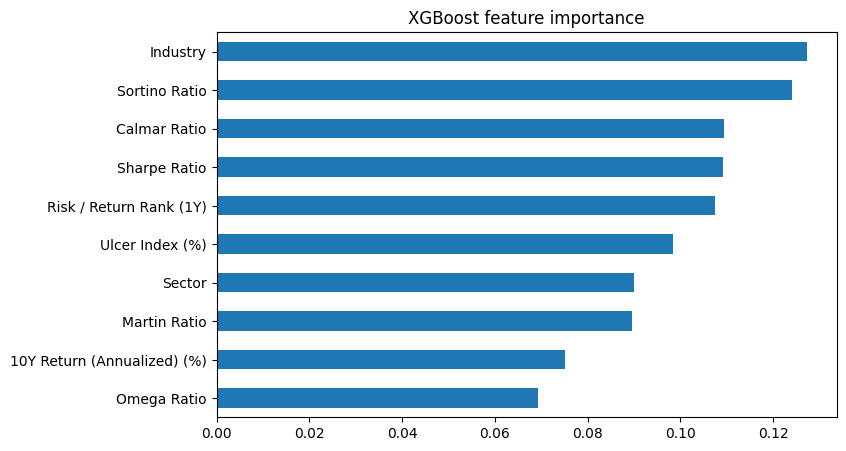

In [180]:
## which features does XGBoost rely on most?
pd.Series( classifier.feature_importances_, index=feature_columns ).sort_values().plot.barh( figsize=(8,5) )
plt.title('XGBoost feature importance')
plt.show()

## Compare the models

In [181]:
results_df = pd.DataFrame(results).T.round(3)

results_df

,Accuracy,Precision,Recall,F1
MLP (PyTorch),0.419,0.412,0.419,0.414
DL 2 hidden layers (PyTorch),0.628,0.622,0.628,0.621
XGBoost,0.512,0.514,0.512,0.509


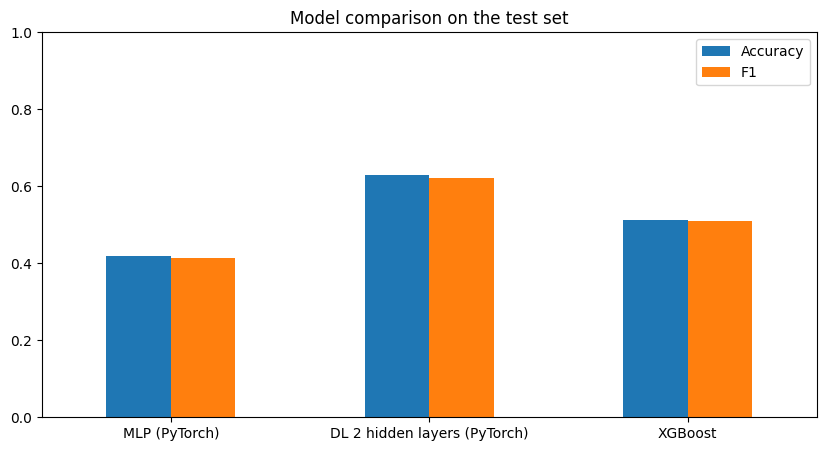

In [182]:
results_df[['Accuracy', 'F1']].plot.bar( figsize=(10,5), rot=0 )
plt.title('Model comparison on the test set')
plt.ylim(0, 1)
plt.show()

## Deploy PyTorch Model

Export the deep learning model to ONNX. The input is the 10 raw features (normalization is inside the model); the network output is converted to an **integer class** with argmax (`torch.max(..., dim=1)`), both here and in `index.js` on the web page.

In [183]:
os.makedirs('deploy', exist_ok=True)

model_dl.eval()

dummy_input = torch.randn(1, n_features)

input_names  = ["input1"]
output_names = ["output1"]

export_args = dict(
        verbose=False,
        opset_version = 15,       ## opset 15
        input_names = input_names,
        output_names = output_names,
        dynamic_axes = {"input1": {0: "batch"}, "output1": {0: "batch"}}
)

try:
    torch.onnx.export(model_dl, dummy_input, "deploy/DLnet_StockStrategy.onnx", dynamo=False, **export_args)
except TypeError:      ## older PyTorch versions do not have the dynamo argument
    torch.onnx.export(model_dl, dummy_input, "deploy/DLnet_StockStrategy.onnx", **export_args)

/tmp/ipykernel_1877/3733148724.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_dl, dummy_input, "deploy/DLnet_StockStrategy.onnx", dynamo=False, **export_args)


## Validate the PyTorch ONNX model

In [184]:
sess = rt.InferenceSession('deploy/DLnet_StockStrategy.onnx')

print('opset:', onnx.load('deploy/DLnet_StockStrategy.onnx').opset_import)

input_name = sess.get_inputs()[0].name
label_name = sess.get_outputs()[0].name

print(input_name, label_name)

opset: [version: 15
]
input1 output1


In [185]:
pred_ort = sess.run(  [label_name], {input_name: X_test.astype(np.float32)}  )

pred_ort[0][:5]

array([[3.37582031e-22, 2.40884151e-06, 9.99997616e-01],
       [9.99994993e-01, 4.94759388e-06, 2.90853242e-15],
       [1.23098065e-08, 1.00000000e+00, 1.36325776e-19],
       [1.25287566e-04, 3.90686296e-18, 9.99874711e-01],
       [9.99942541e-01, 5.74124424e-05, 1.58226446e-10]], dtype=float32)

In [186]:
preds_onnx = np.argmax( pred_ort[0], axis=1 )     ## integer class, same as torch.max(..., dim=1)

print('Integer predictions (ONNX):', preds_onnx.tolist())

print('Max difference PyTorch vs ONNX probabilities:', np.abs( pred_ort[0] - y_pred_test.numpy() ).max())
print('Same predicted class for all test stocks:', np.array_equal( preds_onnx, np.array(list_preds) ))

print_metrics_function(y_test.ravel(), preds_onnx)

Integer predictions (ONNX): [2, 0, 1, 2, 0, 0, 1, 1, 1, 0, 1, 1, 0, 2, 0, 1, 0, 0, 0, 0, 2, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 2, 0, 1, 2, 0, 0, 0, 2, 2, 0, 1, 2]
Max difference PyTorch vs ONNX probabilities: 5.9604645e-08
Same predicted class for all test stocks: True
Accuracy: 0.63
Confusion Matrix:
[[12  2  4]
 [ 3 10  0]
 [ 5  2  5]]
Precision: 0.622
Recall: 0.628
F1-measure: 0.621


## Deploy XGBoost Model

* ONNX and GitHub

In [187]:
initial_types = [(
          'float_input',
          FloatTensorType(  [None, n_features ]  )
)]

In [188]:
onnx_model = onnxmltools.convert_xgboost(classifier, initial_types=initial_types, target_opset=15)   ## opset 15

onnxmltools.utils.save_model(onnx_model, 'deploy/xgboost_StockStrategy_ort.onnx')

In [189]:
sess_xgb = rt.InferenceSession('deploy/xgboost_StockStrategy_ort.onnx')

print('opset:', onnx.load('deploy/xgboost_StockStrategy_ort.onnx').opset_import)

input_name_xgb = sess_xgb.get_inputs()[0].name
label_name_xgb = sess_xgb.get_outputs()[0].name

print(input_name_xgb, label_name_xgb)

opset: [domain: "ai.onnx.ml"
version: 1
]
float_input label


In [190]:
pred_ort_xgb = sess_xgb.run(  [label_name_xgb], {input_name_xgb: X_test.astype(np.float32)}  )

print('Same predicted class as XGBoost for all test stocks:', np.array_equal( pred_ort_xgb[0], y_pred_xgb ))

Same predicted class as XGBoost for all test stocks: True


## Save the label maps for the web page

The GitHub Pages site reads this file to fill the Sector / Industry drop-downs and to name the predicted strategy.

In [191]:
example = X_test[0].tolist()

site_info = {
    'feature_columns': feature_columns,
    'sector_names':    sector_names,
    'industry_names':  industry_names,
    'strategy_names':  strategy_names,
    'example_symbol':  str(sym_test[0]),
    'example_values':  example,
}

with open('deploy/site_info.json', 'w') as f:
    json.dump(site_info, f, indent=2)

os.listdir('deploy')

['xgboost_StockStrategy_ort.onnx',
 'site_info.json',
 'DLnet_StockStrategy.onnx']

In [192]:
## copy the deployment files to Google Drive
import shutil
shutil.copytree('deploy', '/content/drive/MyDrive/HW3/deploy', dirs_exist_ok=True)

'/content/drive/MyDrive/HW3/deploy'